# SimulaHub · Módulo 1 – CFD e Modelagem Hemodinâmica
## Dia 1 (03/11) – Da pressão ao movimento dos fluidos
**Atividade prática da tarde** · Docente: Profª. Drª. Rita de Cássia dos Anjos (UFSCar) · Tutor: Willian Costa de Paula (UTFPR)

---

**Pergunta-guia do curso:** *como a geometria de um vaso influencia o fluxo sanguíneo?*

Neste notebook vamos transformar em números e gráficos os conceitos vistos pela manhã:

1. **Pressão hidrostática:** $P = P_0 + \rho g h$ e sua relação com a pressão arterial.
2. **Vazão e velocidade:** $Q = \Delta V / \Delta t$ e $Q = A\,v$.
3. **Continuidade:** o que acontece com a velocidade quando a seção do vaso diminui (estenose).
4. **Bernoulli:** o que acontece com a pressão nessa mesma região.
5. **Exploração interativa** dos parâmetros.

Ao final há **4 exercícios para entregar**.

### Como usar este notebook no Google Colab
- Execute as células **em ordem**, de cima para baixo, com `Shift + Enter`.
- Células de **texto** (como esta) explicam a física; células de **código** fazem os cálculos. Em cada linha de código há um comentário (após o símbolo `#`) explicando o que ela faz.
- Se algo der errado, use **Ambiente de execução → Reiniciar e executar tudo**.

## 0. Preparação: bibliotecas e constantes
Usaremos duas bibliotecas do Python:
- **NumPy**, para cálculos com vetores de números;
- **Matplotlib**, para gerar gráficos.

In [1]:
import numpy as np                        # importa o NumPy com o apelido "np" (cálculos numéricos com vetores)
import matplotlib.pyplot as plt           # importa o módulo de gráficos do Matplotlib com o apelido "plt"

plt.rcParams["figure.figsize"] = (8, 5)   # tamanho padrão das figuras: 8 x 5 polegadas
plt.rcParams["font.size"] = 12            # tamanho padrão do texto nos gráficos
plt.rcParams["axes.grid"] = True          # liga uma grade de fundo em todos os gráficos

Agora definimos as **constantes físicas** que usaremos ao longo do notebook. Trabalharemos sempre no **Sistema Internacional (SI)** e converteremos para unidades clínicas apenas na hora de mostrar resultados.

A unidade clínica de pressão é o **milímetro de mercúrio (mmHg)**: $1\ \text{mmHg} \approx 133{,}322\ \text{Pa}$, em que Pa é o **pascal** ($1\ \text{Pa} = 1\ \text{N/m}^2$).

In [2]:
rho = 1060.0       # densidade típica do sangue, em kg/m³
g = 9.81           # aceleração da gravidade, em m/s²
MMHG = 133.322     # quantos pascals (Pa) existem em 1 mmHg

def pa_para_mmhg(p_pa):         # define uma função que recebe uma pressão em pascal...
    return p_pa / MMHG          # ...e devolve o valor correspondente em mmHg

print(f"Densidade do sangue: {rho} kg/m³")         # mostra o valor da densidade na tela
print(f"1 mmHg = {MMHG} Pa")                         # mostra o fator de conversão
print(f"Teste: 13332,2 Pa = {pa_para_mmhg(13332.2):.1f} mmHg")  # testa a função: deve dar 100,0 mmHg

Densidade do sangue: 1060.0 kg/m³
1 mmHg = 133.322 Pa
Teste: 13332,2 Pa = 100.0 mmHg


---
## 1. Fluido em repouso: pressão hidrostática

Pressão é **força por unidade de área**, $P = F/A$. Em um fluido em repouso, cada camada sustenta o peso do fluido acima dela. O equilíbrio de forças em uma pequena fatia leva a

$$\frac{dP}{dz} = -\rho g \quad\Longrightarrow\quad P(h) = P_0 + \rho g h,$$

em que $h$ é a profundidade abaixo do ponto de referência, onde a pressão vale $P_0$. Pelo **princípio de Pascal**, uma variação de $P_0$ é transmitida igualmente a todos os pontos do fluido.

Vamos calcular e visualizar essa relação para uma coluna de sangue.

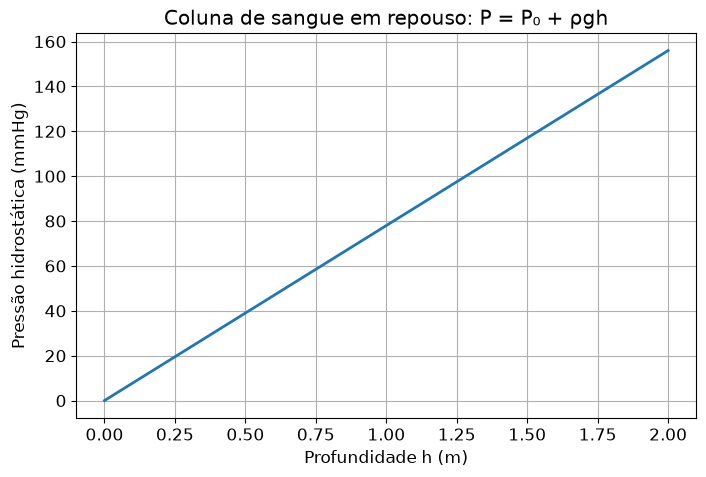

A cada 10 cm de profundidade a pressão aumenta 7.8 mmHg


In [3]:
P0 = 0.0                              # pressão no topo da coluna (pressão manométrica: medimos acima da atmosférica)
h = np.linspace(0.0, 2.0, 200)        # 200 profundidades igualmente espaçadas entre 0 e 2 metros
P = P0 + rho * g * h                  # aplica P = P0 + ρgh a todos os valores de h de uma só vez

plt.plot(h, pa_para_mmhg(P), lw=2, color="tab:blue")       # desenha a curva pressão (mmHg) × profundidade
plt.xlabel("Profundidade h (m)")                            # rótulo do eixo horizontal
plt.ylabel("Pressão hidrostática (mmHg)")                   # rótulo do eixo vertical
plt.title("Coluna de sangue em repouso: P = P₀ + ρgh")      # título do gráfico
plt.show()                                                   # exibe a figura

print(f"A cada 10 cm de profundidade a pressão aumenta {pa_para_mmhg(rho*g*0.10):.1f} mmHg")  # taxa de aumento

**Interpretação:** a relação é **linear**: dobrar a profundidade dobra o acréscimo de pressão. Para o sangue, cada 10 cm de coluna correspondem a cerca de 7,8 mmHg.

### 1.1 Aplicação: pressão arterial em uma pessoa em pé
Tomemos o coração como referência, com pressão arterial média de **100 mmHg** (valor ilustrativo). Em uma pessoa em pé, a cabeça fica cerca de **0,4 m acima** do coração e os pés cerca de **1,2 m abaixo**. Ignorando o escoamento (apenas o efeito hidrostático), qual é a pressão em cada lugar?

Cabeça  :   68.8 mmHg
Coração :  100.0 mmHg
Pés     :  193.6 mmHg


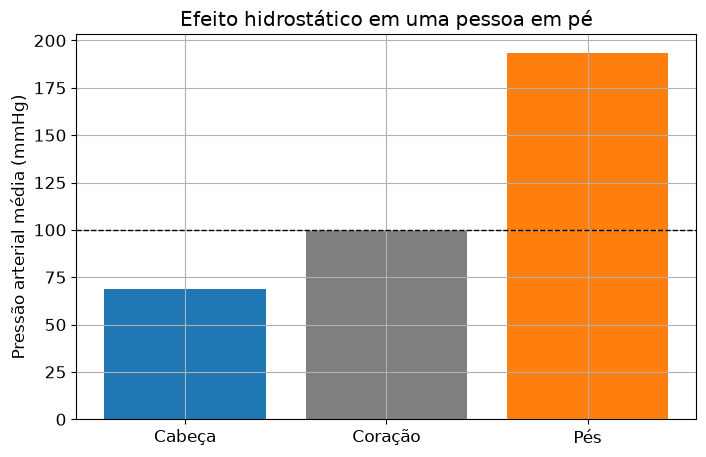

In [4]:
P_coracao = 100.0                                  # pressão arterial média no coração, em mmHg (valor ilustrativo)
locais = ["Cabeça", "Coração", "Pés"]              # nomes dos três pontos do corpo
alturas = np.array([-0.4, 0.0, 1.2])               # profundidade em relação ao coração (m); negativo = acima

P_locais = P_coracao + pa_para_mmhg(rho * g * alturas)   # P = P_coração + ρgh, convertido para mmHg

for nome, p in zip(locais, P_locais):                    # percorre os pares (nome, pressão)
    print(f"{nome:8s}: {p:6.1f} mmHg")                   # mostra cada pressão com uma casa decimal

plt.bar(locais, P_locais, color=["tab:blue", "tab:gray", "tab:orange"])   # gráfico de barras
plt.axhline(P_coracao, ls="--", color="k", lw=1)          # linha tracejada com o valor no coração
plt.ylabel("Pressão arterial média (mmHg)")                # rótulo do eixo vertical
plt.title("Efeito hidrostático em uma pessoa em pé")       # título
plt.show()                                                 # exibe a figura

**Interpretação:** só pela gravidade, a pressão nos pés é quase o dobro da pressão no coração, e a da cabeça é cerca de 30% menor. É por isso que a pressão arterial é medida no braço, aproximadamente **na altura do coração**.

---
## 2. Fluido em movimento: vazão e velocidade

A **vazão volumétrica** é o volume que atravessa uma seção por unidade de tempo:

$$Q = \frac{\Delta V}{\Delta t}.$$

Se a velocidade média do fluido na seção é $v$ e a área da seção é $A$, então em um intervalo $\Delta t$ passa um "cilindro" de volume $A\,v\,\Delta t$. Logo,

$$Q = A\,v \quad\Longrightarrow\quad v = \frac{Q}{A}.$$

### 2.1 Vazão a partir do coração
O coração ejeta um **volume sistólico** de cerca de 70 mL por batimento, a cerca de 72 batimentos por minuto.

In [5]:
V_batimento = 70e-6        # volume sistólico: 70 mL = 70 × 10⁻⁶ m³
freq_bpm = 72              # frequência cardíaca, em batimentos por minuto
dt = 60.0 / freq_bpm       # duração de um batimento, em segundos (60 s divididos por 72 batimentos)

Q = V_batimento / dt       # vazão média: Q = ΔV/Δt, em m³/s
Q_lmin = Q * 1e3 * 60      # conversão para litros por minuto (1 m³ = 1000 L; 1 min = 60 s)

print(f"Duração de um batimento: {dt:.3f} s")    # mostra Δt
print(f"Vazão média Q = {Q:.2e} m³/s")             # mostra Q em notação científica
print(f"Vazão média Q = {Q_lmin:.2f} L/min")       # mostra Q em L/min (o "débito cardíaco")

Duração de um batimento: 0.833 s
Vazão média Q = 8.40e-05 m³/s
Vazão média Q = 5.04 L/min


O resultado, cerca de 5 L/min, é o **débito cardíaco** típico em repouso. Agora calculamos a velocidade média do sangue na aorta, cujo raio típico é de cerca de 1,25 cm.

In [6]:
r_aorta = 1.25e-2               # raio da aorta: 1,25 cm = 0,0125 m
A_aorta = np.pi * r_aorta**2    # área da seção circular: A = π r²
v_aorta = Q / A_aorta           # velocidade média pela relação Q = A v

print(f"Área da aorta: {A_aorta*1e4:.2f} cm²")        # 1 m² = 10⁴ cm²
print(f"Velocidade média na aorta: {v_aorta*100:.1f} cm/s")   # 1 m/s = 100 cm/s

Área da aorta: 4.91 cm²
Velocidade média na aorta: 17.1 cm/s


### 2.2 Como a velocidade depende do raio, com a vazão fixa?
Como $A = \pi r^2$, temos $v = Q/(\pi r^2)$: a velocidade é **inversamente proporcional ao quadrado do raio**. Reduzir o raio pela metade multiplica a velocidade por 4.

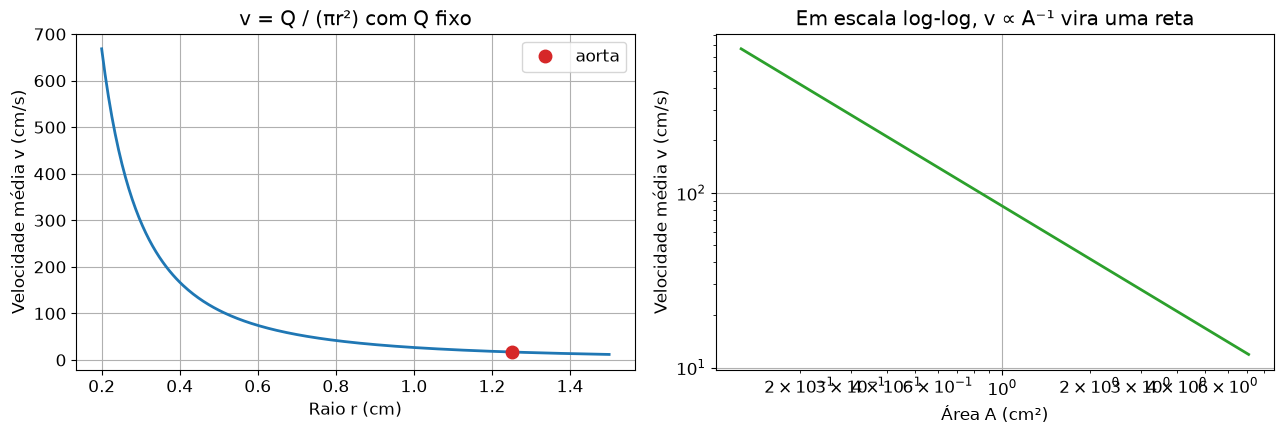

In [7]:
r = np.linspace(0.2e-2, 1.5e-2, 300)    # 300 raios entre 0,2 cm e 1,5 cm (em metros)
A = np.pi * r**2                          # área correspondente a cada raio
v = Q / A                                 # velocidade média para a mesma vazão Q

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))      # cria uma figura com dois gráficos lado a lado

ax[0].plot(r*100, v*100, lw=2)                        # gráfico 1: velocidade (cm/s) × raio (cm)
ax[0].plot(r_aorta*100, v_aorta*100, "o", ms=9, color="tab:red", label="aorta")  # marca o ponto da aorta
ax[0].set_xlabel("Raio r (cm)")                       # rótulo do eixo x
ax[0].set_ylabel("Velocidade média v (cm/s)")         # rótulo do eixo y
ax[0].set_title("v = Q / (πr²) com Q fixo")           # título
ax[0].legend()                                         # mostra a legenda

ax[1].loglog(A*1e4, v*100, lw=2, color="tab:green")   # gráfico 2: v × A em escala logarítmica nos dois eixos
ax[1].set_xlabel("Área A (cm²)")                      # rótulo do eixo x
ax[1].set_ylabel("Velocidade média v (cm/s)")         # rótulo do eixo y
ax[1].set_title("Em escala log-log, v ∝ A⁻¹ vira uma reta")   # título

plt.tight_layout()                                     # ajusta os espaçamentos entre os gráficos
plt.show()                                             # exibe a figura

**Interpretação:** à esquerda, a velocidade cresce rapidamente quando o raio diminui. À direita, em escala log-log, a relação $v \propto A^{-1}$ aparece como uma reta de inclinação $-1$.

---
## 3. Conservação de massa: o vaso com estenose

Para um fluido **incompressível** (densidade constante), a massa que entra em um trecho de vaso é igual à que sai. Portanto, a vazão é a mesma em todas as seções:

$$Q = A_1 v_1 = A_2 v_2 \quad\Longrightarrow\quad \frac{v_2}{v_1} = \frac{A_1}{A_2} = \left(\frac{r_1}{r_2}\right)^2.$$

Esta é a **equação da continuidade**. Vamos aplicá-la a um vaso com uma **estenose** (estreitamento). Modelaremos o raio ao longo do eixo $x$ do vaso com uma "depressão" suave em forma de gaussiana:

$$r(x) = r_0\left[1 - s\,e^{-x^2/(2\sigma^2)}\right],$$

em que $s$ é a **fração de redução do diâmetro** na garganta (por exemplo, $s = 0{,}5$ significa 50% de estreitamento) e $\sigma$ controla o comprimento da estenose.

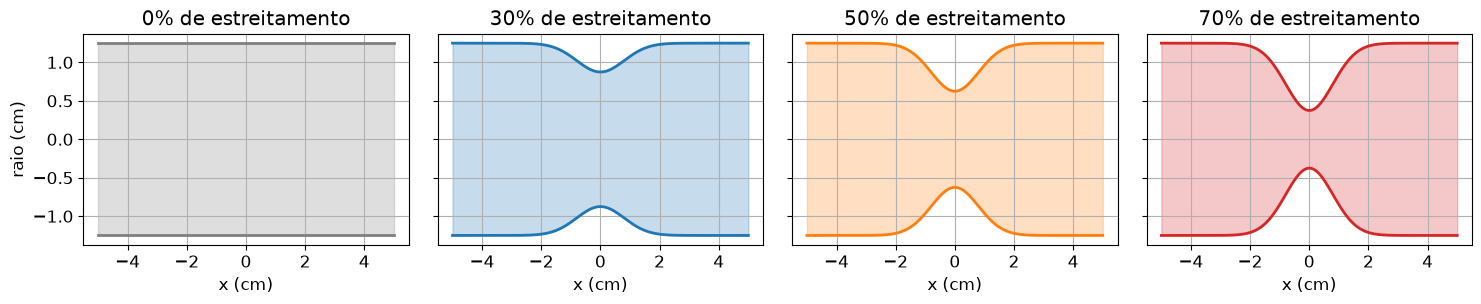

In [8]:
def raio_vaso(x, r0, s, sigma=0.8e-2):
    # x     : posições ao longo do eixo do vaso (m); x = 0 é o centro da estenose
    # r0    : raio do vaso saudável (m)
    # s     : fração de redução do diâmetro na garganta (0 = sem estenose; 0,7 = 70%)
    # sigma : "largura" da estenose (m); quanto maior, mais longo o estreitamento
    return r0 * (1 - s * np.exp(-x**2 / (2 * sigma**2)))   # raio em cada posição x

x = np.linspace(-5e-2, 5e-2, 500)          # 500 posições entre -5 cm e +5 cm ao longo do vaso
r0 = r_aorta                                # usamos o raio da aorta como raio do vaso saudável
cenarios = [0.0, 0.3, 0.5, 0.7]             # os quatro cenários do curso: 0%, 30%, 50% e 70%
cores = ["tab:gray", "tab:blue", "tab:orange", "tab:red"]   # uma cor para cada cenário

fig, axs = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)   # quatro gráficos lado a lado, mesmo eixo y
for ax, s, c in zip(axs, cenarios, cores):                     # percorre cenários, eixos e cores juntos
    rx = raio_vaso(x, r0, s)                                    # raio do vaso em cada posição
    ax.fill_between(x*100, -rx*100, rx*100, color=c, alpha=0.25)   # pinta o interior do vaso (lúmen)
    ax.plot(x*100, rx*100, color=c, lw=2)                        # parede superior
    ax.plot(x*100, -rx*100, color=c, lw=2)                       # parede inferior (simétrica)
    ax.set_title(f"{int(s*100)}% de estreitamento")              # título com o cenário
    ax.set_xlabel("x (cm)")                                      # rótulo do eixo x
axs[0].set_ylabel("raio (cm)")                                   # rótulo do eixo y só no primeiro gráfico
plt.tight_layout()                                               # ajusta os espaçamentos
plt.show()                                                       # exibe a figura

Agora aplicamos $v(x) = Q / A(x)$ em cada posição, mantendo a **mesma vazão** em todos os cenários.

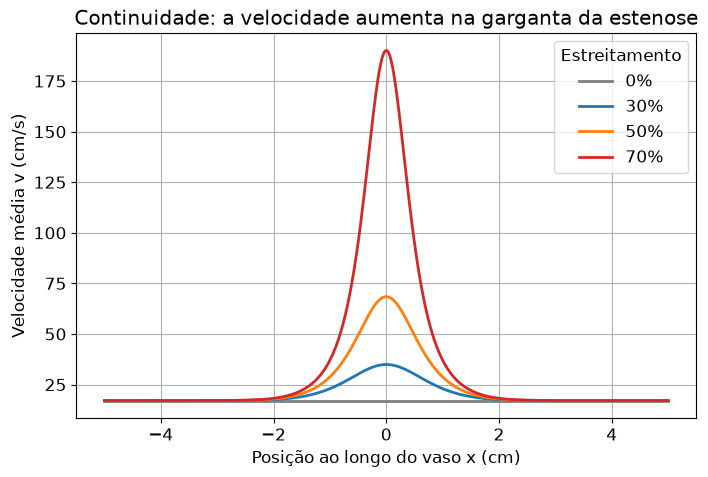

Estreitamento | v_garganta / v0
     0%      |     1.0
    30%      |     2.0
    50%      |     4.0
    70%      |    11.1


In [9]:
for s, c in zip(cenarios, cores):                      # percorre os cenários e suas cores
    A_x = np.pi * raio_vaso(x, r0, s)**2               # área da seção em cada posição x
    v_x = Q / A_x                                      # continuidade: v(x) = Q / A(x)
    plt.plot(x*100, v_x*100, color=c, lw=2, label=f"{int(s*100)}%")   # curva de velocidade do cenário

plt.xlabel("Posição ao longo do vaso x (cm)")          # rótulo do eixo x
plt.ylabel("Velocidade média v (cm/s)")                # rótulo do eixo y
plt.title("Continuidade: a velocidade aumenta na garganta da estenose")   # título
plt.legend(title="Estreitamento")                      # legenda com título
plt.show()                                             # exibe a figura

print("Estreitamento | v_garganta / v0")               # cabeçalho da tabela
for s in cenarios:                                     # para cada cenário...
    razao = 1 / (1 - s)**2                             # ...razão de velocidades: (r0 / r_garganta)²
    print(f"   {int(s*100):3d}%      |   {razao:5.1f}")   # mostra a linha da tabela

**Interpretação:** com 70% de redução do diâmetro, a área da garganta cai para $(0{,}3)^2 = 9\%$ da original, e a velocidade aumenta cerca de **11 vezes**. Esses são os mesmos valores dos cenários que usaremos com o SimVascular no Dia 4.

---
## 4. E a pressão? Introdução à equação de Bernoulli

Para um fluido **ideal** (sem viscosidade), incompressível e em regime estacionário, ao longo de uma linha de corrente horizontal vale a **equação de Bernoulli**:

$$P + \tfrac{1}{2}\rho v^2 = \text{constante} \quad\Longrightarrow\quad P(x) = P_1 + \tfrac{1}{2}\rho\left[v_1^2 - v(x)^2\right].$$

Onde a velocidade **aumenta**, a pressão **diminui**: a energia de pressão é convertida em energia cinética. Vamos supor uma pressão de 100 mmHg na entrada do vaso.

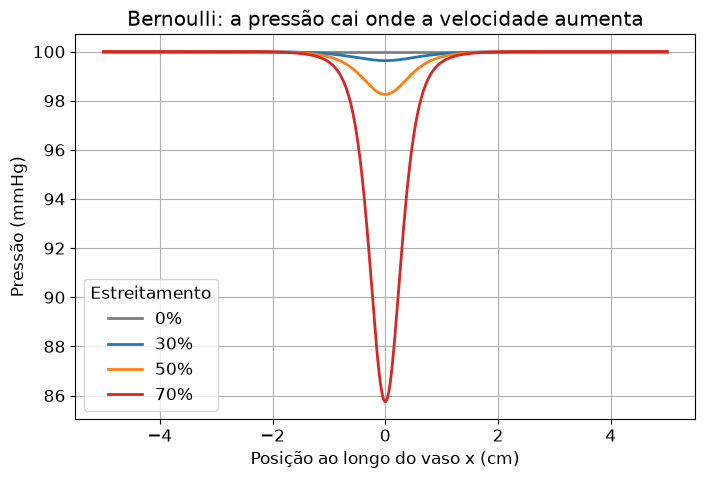

In [10]:
P_entrada = 100.0 * MMHG                       # pressão na entrada do vaso: 100 mmHg convertidos para Pa
v_entrada = v_aorta                            # velocidade na entrada (região sem estenose)

for s, c in zip(cenarios, cores):              # percorre os cenários
    v_x = Q / (np.pi * raio_vaso(x, r0, s)**2) # velocidade em cada posição (continuidade)
    P_x = P_entrada + 0.5 * rho * (v_entrada**2 - v_x**2)   # Bernoulli: pressão em cada posição, em Pa
    plt.plot(x*100, pa_para_mmhg(P_x), color=c, lw=2, label=f"{int(s*100)}%")   # curva em mmHg

plt.xlabel("Posição ao longo do vaso x (cm)")  # rótulo do eixo x
plt.ylabel("Pressão (mmHg)")                   # rótulo do eixo y
plt.title("Bernoulli: a pressão cai onde a velocidade aumenta")   # título
plt.legend(title="Estreitamento")              # legenda
plt.show()                                     # exibe a figura

In [11]:
print("Estreitamento | v_garganta (cm/s) | queda de pressão na garganta (mmHg)")   # cabeçalho
for s in cenarios:                                    # para cada cenário...
    v_g = v_entrada / (1 - s)**2                      # velocidade na garganta pela continuidade
    dP = 0.5 * rho * (v_g**2 - v_entrada**2)          # queda de pressão de Bernoulli, em Pa
    print(f"   {int(s*100):3d}%      |   {v_g*100:7.1f}         |   {pa_para_mmhg(dP):6.2f}")   # linha da tabela

Estreitamento | v_garganta (cm/s) | queda de pressão na garganta (mmHg)
     0%      |      17.1         |     0.00
    30%      |      34.9         |     0.37
    50%      |      68.4         |     1.75
    70%      |     190.1         |    14.26


**Interpretação e limitação importante:**
- A queda de pressão cresce muito rápido com o estreitamento, porque depende de $v^2$, e $v \propto 1/r^2$; logo, $\Delta P$ cresce como $1/r^4$.
- No modelo ideal, a pressão **volta exatamente ao valor inicial** depois da estenose. Em um vaso real isso **não acontece**: parte da energia é dissipada pela **viscosidade** e pelas recirculações após a garganta. É exatamente isso que estudaremos no **Dia 2** (viscosidade, Reynolds e Navier–Stokes) e veremos nas simulações dos Dias 3 e 4.

---
## 5. Exploração interativa
Execute a célula abaixo e mova os controles para variar o **grau de estenose** e o **débito cardíaco**. Observe como geometria, velocidade e pressão respondem juntas.

In [12]:
from ipywidgets import interact, FloatSlider       # importa as ferramentas de controles interativos

def explorar(estreitamento=0.5, debito_L_min=5.0):
    s = estreitamento                                  # fração de redução do diâmetro escolhida no controle
    Qi = debito_L_min * 1e-3 / 60                      # converte a vazão escolhida de L/min para m³/s
    rx = raio_vaso(x, r0, s)                           # raio em cada posição
    vx = Qi / (np.pi * rx**2)                          # velocidade pela continuidade
    v1 = Qi / (np.pi * r0**2)                          # velocidade na região saudável
    Px = 100 * MMHG + 0.5 * rho * (v1**2 - vx**2)      # pressão por Bernoulli (entrada a 100 mmHg)

    fig, ax = plt.subplots(3, 1, figsize=(8, 8), sharex=True)        # três gráficos empilhados, mesmo eixo x
    ax[0].fill_between(x*100, -rx*100, rx*100, color="tab:red", alpha=0.25)   # geometria do vaso
    ax[0].set_ylabel("raio (cm)")                                      # rótulo
    ax[0].set_title(f"Estreitamento {s*100:.0f}% · Q = {debito_L_min:.1f} L/min")   # título com os parâmetros
    ax[1].plot(x*100, vx*100, lw=2)                                    # perfil de velocidade
    ax[1].set_ylabel("v (cm/s)")                                       # rótulo
    ax[2].plot(x*100, pa_para_mmhg(Px), lw=2, color="tab:orange")      # perfil de pressão
    ax[2].set_ylabel("P (mmHg)")                                       # rótulo
    ax[2].set_xlabel("x (cm)")                                         # rótulo do eixo x
    plt.tight_layout()                                                 # ajusta espaçamentos
    plt.show()                                                         # exibe a figura

interact(explorar,                                                                  # liga a função aos controles
         estreitamento=FloatSlider(min=0.0, max=0.8, step=0.05, value=0.5, description="Estenose"),   # 0 a 80%
         debito_L_min=FloatSlider(min=2.0, max=25.0, step=0.5, value=5.0, description="Q (L/min)"));  # 2 a 25 L/min

interactive(children=(FloatSlider(value=0.5, description='Estenose', max=0.8, step=0.05), FloatSlider(value=5.…

---
## Resumo do dia
| Conceito | Equação | O que aprendemos |
|---|---|---|
| Hidrostática | $P = P_0 + \rho g h$ | a pressão cresce linearmente com a profundidade |
| Vazão | $Q = \Delta V/\Delta t = A v$ | a mesma vazão exige maior velocidade em seções menores |
| Continuidade | $A_1 v_1 = A_2 v_2$ | em uma estenose de 70% a velocidade aumenta cerca de 11 vezes |
| Bernoulli | $P + \tfrac12\rho v^2 = \text{cte}$ | onde a velocidade aumenta, a pressão diminui |

**Resultado esperado do dia:** compreender por que diferenças de pressão geram movimento, como a continuidade relaciona área e velocidade e por que uma estenose altera o escoamento.

---
# Exercícios para entregar

**Instruções de entrega**
- Resolva cada exercício **nas células indicadas**, logo abaixo do enunciado. Você pode criar células novas se precisar.
- Todos os gráficos devem ter **eixos rotulados com unidades** e título.
- As respostas discursivas devem ser escritas em células de texto.
- Ao terminar, use **Ambiente de execução → Reiniciar e executar tudo** para conferir que o notebook roda sem erros.
- Baixe o arquivo em **Arquivo → Fazer download → Fazer download do .ipynb**, nomeie como `NomeSobrenome_Dia1.ipynb` e envie até **[prazo a definir pela docente]**.

### Exercício 1 – Hidrostática: humano × girafa
Em uma girafa adulta, a cabeça fica cerca de **2,0 m acima** do coração; em um humano em pé, cerca de **0,4 m**.

a) Calcule, em mmHg, a diferença de pressão hidrostática entre o coração e a cabeça para os dois casos (use $\rho$ do sangue).

b) Faça **um único gráfico** com a diferença de pressão (mmHg) em função da altura acima do coração, de 0 a 2,5 m, marcando os pontos do humano e da girafa.

c) Se a pressão na cabeça precisa ser de pelo menos ~60 mmHg para irrigar o cérebro, qual deve ser, no mínimo, a pressão média no coração da girafa? Responda em uma célula de texto.

Item (a):
Diferença de pressão hidrostática no humano (0,4 m): 31.20 mmHg (4159.4 Pa)
Diferença de pressão hidrostática na girafa (2,0 m): 155.99 mmHg (20797.2 Pa)


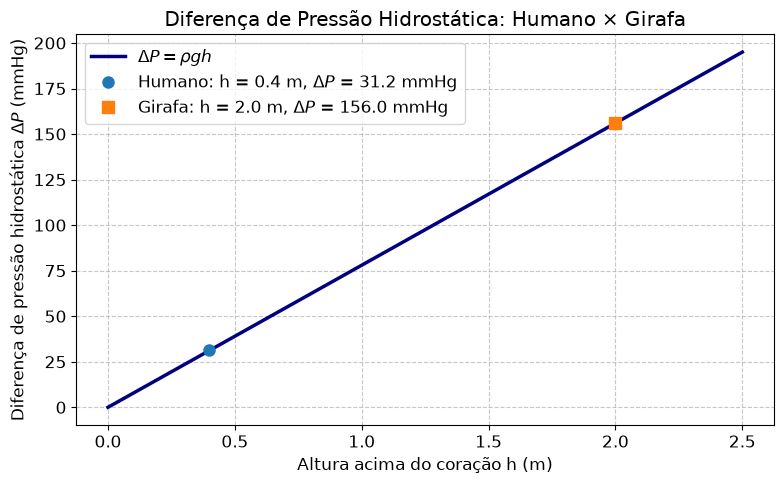

In [13]:
# Exercício 1 – Resolução dos itens (a) e (b)

# a) Diferença de pressão hidrostática: ΔP = ρ * g * Δh
h_humano = 0.4   # metros acima do coração
h_girafa = 2.0   # metros acima do coração

delta_P_humano_pa = rho * g * h_humano
delta_P_girafa_pa = rho * g * h_girafa

delta_P_humano_mmhg = pa_para_mmhg(delta_P_humano_pa)
delta_P_girafa_mmhg = pa_para_mmhg(delta_P_girafa_pa)

print(f"Item (a):")
print(f"Diferença de pressão hidrostática no humano (0,4 m): {delta_P_humano_mmhg:.2f} mmHg ({delta_P_humano_pa:.1f} Pa)")
print(f"Diferença de pressão hidrostática na girafa (2,0 m): {delta_P_girafa_mmhg:.2f} mmHg ({delta_P_girafa_pa:.1f} Pa)")

# b) Gráfico de ΔP (mmHg) em função da altura acima do coração (0 a 2,5 m)
h_vals = np.linspace(0.0, 2.5, 200)
delta_P_vals_mmhg = pa_para_mmhg(rho * g * h_vals)

plt.figure(figsize=(8, 5))
plt.plot(h_vals, delta_P_vals_mmhg, lw=2.5, color="navy", label=r"$\Delta P = \rho g h$")
plt.plot(h_humano, delta_P_humano_mmhg, "o", ms=8, color="tab:blue", 
         label=rf"Humano: h = {h_humano} m, $\Delta P$ = {delta_P_humano_mmhg:.1f} mmHg")
plt.plot(h_girafa, delta_P_girafa_mmhg, "s", ms=8, color="tab:orange", 
         label=rf"Girafa: h = {h_girafa} m, $\Delta P$ = {delta_P_girafa_mmhg:.1f} mmHg")

plt.xlabel("Altura acima do coração h (m)")
plt.ylabel(r"Diferença de pressão hidrostática $\Delta P$ (mmHg)")
plt.title("Diferença de Pressão Hidrostática: Humano × Girafa")
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


### Resposta do Exercício 1 (c)

Para garantir uma perfusão cerebral adequada, a pressão arterial na cabeça da girafa deve ser de pelo menos {\text{cabeça}} \approx 60\text{ mmHg}$.

Como a cabeça está a uma altura de  = 2{,}0\text{ m}$ acima do nível do coração, a coluna hidrostática impõe uma redução gravitacional de pressão dada por:
30230P_{\text{cabeça}} = P_{\text{coração}} - \rho g h \implies P_{\text{coração}} = P_{\text{cabeça}} + \Delta P_{\text{hidrostática}}30230

Substituindo os valores calculados:
30230\Delta P_{\text{hidrostática}} \approx 156{,}0\text{ mmHg}30230
30230P_{\text{coração, mín}} = 60\text{ mmHg} + 156{,}0\text{ mmHg} = \mathbf{216{,}0\text{ mmHg}}30230

Portanto, a pressão arterial média no coração da girafa deve ser de no **mínimo ~216 mmHg** (com picos sistólicos frequentemente superando 280–300 mmHg). Essa adaptação fisiológica notável explica por que as girafas possuem um ventrículo esquerdo hipertrofiado com paredes miocárdicas espessas e mecanismos vasomotores especializados para suportar pressões tão elevadas sem sofrer danos vasculares.


### Exercício 2 – Débito cardíaco em exercício físico
Durante exercício intenso, o débito cardíaco pode chegar a cerca de **20 L/min**.

a) Calcule a velocidade média do sangue na aorta (raio 1,25 cm) em repouso (5 L/min) e em exercício (20 L/min).

b) Faça um gráfico da velocidade média na aorta (cm/s) em função do débito cardíaco, de 3 a 25 L/min.

c) Que tipo de curva você obteve? Justifique a partir de $Q = A v$, em uma célula de texto.

Item (a):
Em repouso (5 L/min):    v = 0.1698 m/s = 16.98 cm/s
Em exercício (20 L/min):  v = 0.6791 m/s = 67.91 cm/s


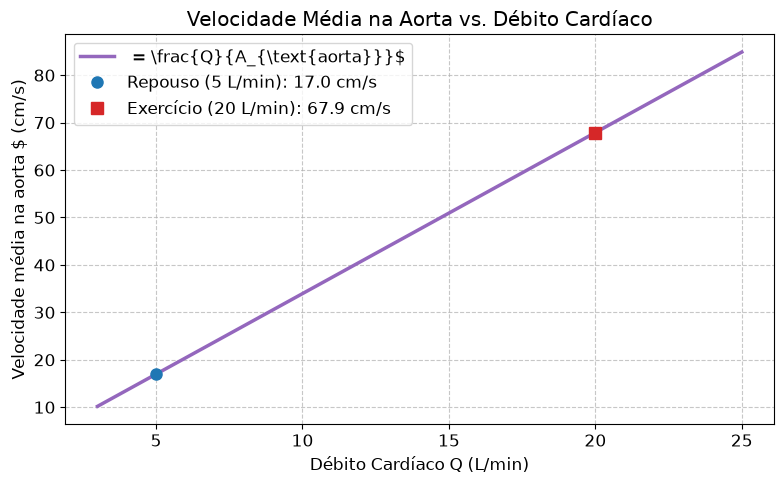

In [14]:
# Exercício 2 – Resolução dos itens (a) e (b)

# a) Velocidades médias na aorta
# Vazões dadas em L/min convertidas para m³/s: Q [m³/s] = Q [L/min] * 1e-3 / 60
Q_repouso_lmin = 5.0
Q_exercicio_lmin = 20.0

Q_repouso = Q_repouso_lmin * 1e-3 / 60.0
Q_exercicio = Q_exercicio_lmin * 1e-3 / 60.0

v_repouso = Q_repouso / A_aorta
v_exercicio = Q_exercicio / A_aorta

print("Item (a):")
print(f"Em repouso (5 L/min):    v = {v_repouso:.4f} m/s = {v_repouso*100:.2f} cm/s")
print(f"Em exercício (20 L/min):  v = {v_exercicio:.4f} m/s = {v_exercicio*100:.2f} cm/s")

# b) Gráfico de v_méd (cm/s) em função do débito cardíaco (3 a 25 L/min)
Q_faixa_lmin = np.linspace(3.0, 25.0, 150)
Q_faixa_m3s = Q_faixa_lmin * 1e-3 / 60.0
v_faixa_cms = (Q_faixa_m3s / A_aorta) * 100.0

plt.figure(figsize=(8, 5))
plt.plot(Q_faixa_lmin, v_faixa_cms, lw=2.5, color="tab:purple", label=r" = \frac{Q}{A_{\text{aorta}}}$")
plt.plot(Q_repouso_lmin, v_repouso*100, "o", ms=8, color="tab:blue", 
         label=f"Repouso ({Q_repouso_lmin:.0f} L/min): {v_repouso*100:.1f} cm/s")
plt.plot(Q_exercicio_lmin, v_exercicio*100, "s", ms=8, color="tab:red", 
         label=f"Exercício ({Q_exercicio_lmin:.0f} L/min): {v_exercicio*100:.1f} cm/s")

plt.xlabel("Débito Cardíaco Q (L/min)")
plt.ylabel("Velocidade média na aorta $ (cm/s)")
plt.title("Velocidade Média na Aorta vs. Débito Cardíaco")
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


### Resposta do Exercício 2 (c)

**Tipo de curva obtida:** A curva obtida é uma **reta** (relação linear direta com intercepto na origem,  = m x$).

**Justificativa matemática a partir de  = A v$:**
Pela equação da continuidade para escoamentos incompressíveis:
30230Q = A \cdot v \implies v = \left(\frac{1}{A}\right) Q30230
Como o vaso sob análise (raiz da aorta) foi modelado com diâmetro fixo ({\text{aorta}} = 1{,}25\text{ cm}$, logo {\text{aorta}} = \pi r_{\text{aorta}}^2 \approx 4{,}91\times 10^{-4}\text{ m}^2 = \text{constante}$), a área transversal $ não varia com a vazão. Portanto, a inclinação /A$ é constante, conferindo uma dependência perfeitamente linear entre velocidade e vazão: quadruplicar o débito cardíaco de \text{ L/min}$ para 0\text{ L/min}$ quadruplica a velocidade média exatamente de 7{,}0\text{ cm/s}$ para 7{,}9\text{ cm/s}$.


### Exercício 3 – Qual estenose multiplica a velocidade por 5?
a) Usando a equação da continuidade, encontre **analiticamente** a fração de redução do diâmetro $s$ para a qual a velocidade na garganta é **5 vezes** a velocidade no vaso saudável. Escreva a dedução em uma célula de texto.

b) Confirme **numericamente**: faça um gráfico de $v_\text{garganta}/v_0$ em função de $s$ (de 0 a 0,8), trace uma linha horizontal em 5 e marque o ponto de cruzamento.

c) Repita o item (b) supondo que o percentual de estenose se refere à **área** (e não ao diâmetro). Qual valor de redução de área gera o mesmo fator 5? Compare os dois resultados.

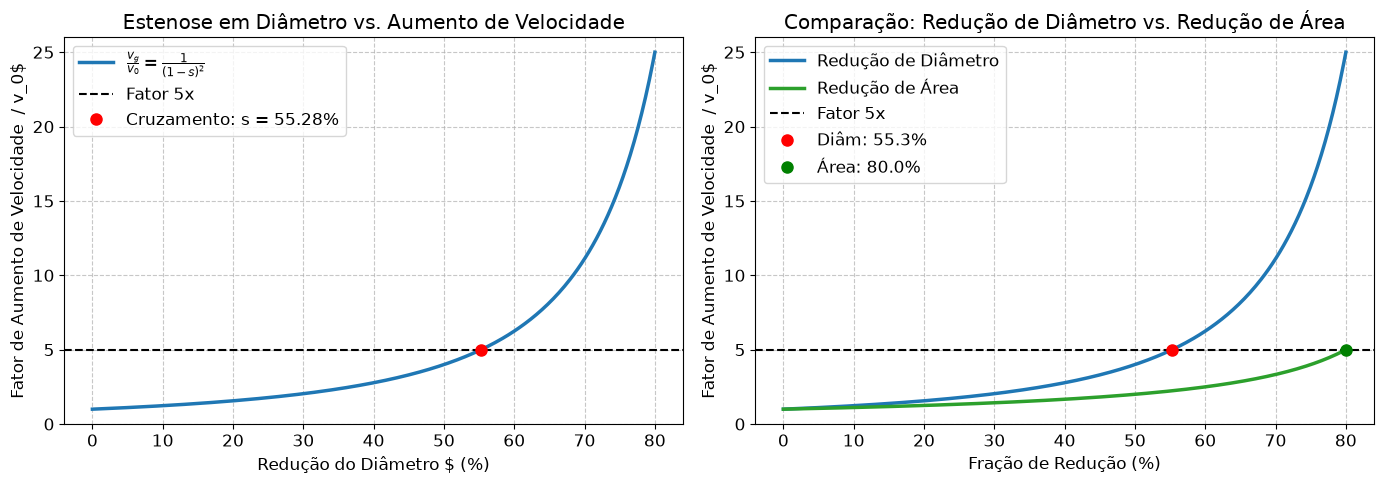

Redução de diâmetro necessária para fator 5x: 55.28%
Redução de área necessária para fator 5x:     80.00%


In [15]:
# Exercício 3 – Resolução dos itens (b) e (c)

# b) Confirmação numérica: gráfico de v_garganta / v0 em função de s (0 a 0.8)
s_vals = np.linspace(0.0, 0.8, 300)
# Redução no diâmetro: raio na garganta r_g = r0 * (1 - s) => v_g / v0 = 1 / (1 - s)^2
razao_v_diametro = 1.0 / (1.0 - s_vals)**2

# Cruzamento analítico: s = 1 - 1/sqrt(5)
s_alvo_diametro = 1.0 - 1.0 / np.sqrt(5.0)

# c) Redução na área: A_g = A0 * (1 - s_area) => v_g / v0 = 1 / (1 - s_area)
s_area_vals = np.linspace(0.0, 0.8, 300)
razao_v_area = 1.0 / (1.0 - s_area_vals)
s_alvo_area = 1.0 - 1.0 / 5.0  # 0.80 (80%)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Redução de Diâmetro
ax[0].plot(s_vals * 100, razao_v_diametro, lw=2.5, color="tab:blue", label=r"$\frac{v_g}{v_0} = \frac{1}{(1-s)^2}$")
ax[0].axhline(5.0, color="k", ls="--", lw=1.5, label="Fator 5x")
ax[0].plot(s_alvo_diametro * 100, 5.0, "ro", ms=8, 
           label=f"Cruzamento: s = {s_alvo_diametro*100:.2f}%")
ax[0].set_xlabel("Redução do Diâmetro $ (%)")
ax[0].set_ylabel("Fator de Aumento de Velocidade  / v_0$")
ax[0].set_title("Estenose em Diâmetro vs. Aumento de Velocidade")
ax[0].set_ylim(0, 26)
ax[0].grid(True, linestyle="--", alpha=0.7)
ax[0].legend()

# Gráfico 2: Comparação Diâmetro vs Área
ax[1].plot(s_vals * 100, razao_v_diametro, lw=2.5, color="tab:blue", label="Redução de Diâmetro")
ax[1].plot(s_area_vals * 100, razao_v_area, lw=2.5, color="tab:green", label="Redução de Área")
ax[1].axhline(5.0, color="k", ls="--", lw=1.5, label="Fator 5x")
ax[1].plot(s_alvo_diametro * 100, 5.0, "ro", ms=8, label=f"Diâm: {s_alvo_diametro*100:.1f}%")
ax[1].plot(s_alvo_area * 100, 5.0, "go", ms=8, label=f"Área: {s_alvo_area*100:.1f}%")
ax[1].set_xlabel("Fração de Redução (%)")
ax[1].set_ylabel("Fator de Aumento de Velocidade  / v_0$")
ax[1].set_title("Comparação: Redução de Diâmetro vs. Redução de Área")
ax[1].set_ylim(0, 26)
ax[1].grid(True, linestyle="--", alpha=0.7)
ax[1].legend()

plt.tight_layout()
plt.show()

print(f"Redução de diâmetro necessária para fator 5x: {s_alvo_diametro*100:.2f}%")
print(f"Redução de área necessária para fator 5x:     {s_alvo_area*100:.2f}%")


### Respostas do Exercício 3 (a) e (c)

#### Dedução Analítica do Item (a):
Pela Equação da Continuidade para fluidos incompressíveis em regime permanente:
30230Q = A_0 v_0 = A_g v_g \implies \frac{v_g}{v_0} = \frac{A_0}{A_g}30230
Para um vaso cilíndrico de diâmetro inicial $, a área da seção normal é:
30230A_0 = \frac{\pi D_0^2}{4}30230
Se há uma redução de diâmetro por uma fração $, o diâmetro na garganta torna-se  = D_0 (1 - s)$. A área correspondente é:
30230A_g = \frac{\pi D_g^2}{4} = \frac{\pi [D_0 (1 - s)]^2}{4} = A_0 (1 - s)^230230
Substituindo na razão de velocidades:
30230\frac{v_g}{v_0} = \frac{A_0}{A_0 (1 - s)^2} = \frac{1}{(1 - s)^2}30230
Para que a velocidade seja multiplicada por 5 ( / v_0 = 5$):
30230\frac{1}{(1 - s)^2} = 5 \implies (1 - s)^2 = \frac{1}{5} \implies 1 - s = \frac{1}{\sqrt{5}}30230
30230s = 1 - \frac{1}{\sqrt{5}} \approx 1 - 0{,}447214 = \mathbf{0{,}5528} \quad (\mathbf{55{,}28\%})30230

---

#### Resposta e Comparação do Item (c):
Quando o percentual de redução refere-se diretamente à **área transversal** ({\text{área}}$):
30230A_g = A_0 (1 - s_{\text{área}}) \implies \frac{v_g}{v_0} = \frac{A_0}{A_g} = \frac{1}{1 - s_{\text{área}}}30230
Igualando ao fator 5:
30230\frac{1}{1 - s_{\text{área}}} = 5 \implies 1 - s_{\text{área}} = \frac{1}{5} = 0{,}20 \implies s_{\text{área}} = 1 - 0{,}20 = \mathbf{0{,}80} \quad (\mathbf{80\%})30230

**Comparação:**
- Uma redução de **55,3% no diâmetro** gera o mesmo impacto na velocidade que uma redução de **80,0% na área** de secção.
- Essa diferença ocorre porque a área escala com o quadrado do diâmetro ( \propto D^2$). Clinicamente, essa distinção é fundamental ao analisar exames de imagem (angiografia biplanar vs. ultrassonografia intravascular / IVUS): uma lesão de 50% em diâmetro já representa perda de 75% da área luminal útil, com expressiva repercussão funcional no miocárdio.


### Exercício 4 – Queda de pressão e os limites do modelo ideal
a) Usando continuidade e Bernoulli, calcule a queda de pressão na garganta (em mmHg) para estenoses de 0% a 80% (passo de 5%), com Q = 5 L/min e raio saudável de 1,25 cm. Faça o gráfico de $\Delta P$ (mmHg) × estreitamento (%).

b) Repita para Q = 20 L/min no **mesmo gráfico**. Por quanto a queda de pressão é multiplicada quando a vazão é multiplicada por 4? Explique por quê.

c) **Discussão (5 a 10 linhas):** o modelo de Bernoulli prevê que a pressão volta ao valor inicial após a estenose. Por que isso não acontece em um vaso real? Que efeitos físicos estão faltando no modelo, e que consequência isso pode ter para o paciente?

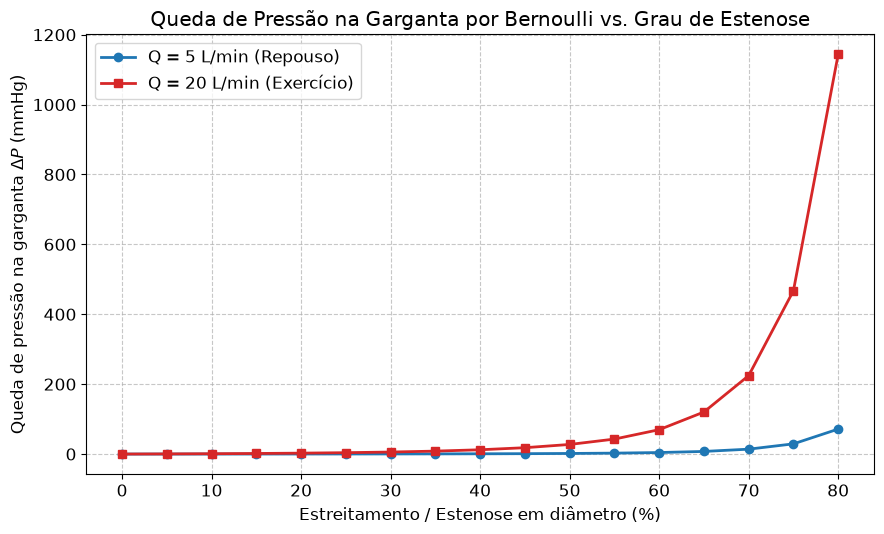

Razão média entre as quedas de pressão (ΔP_20 / ΔP_5): 16.00x
Estenose  0% -> ΔP(5 L/min):    0.00 mmHg | ΔP(20 L/min):    0.00 mmHg
Estenose 20% -> ΔP(5 L/min):    0.17 mmHg | ΔP(20 L/min):    2.64 mmHg
Estenose 40% -> ΔP(5 L/min):    0.77 mmHg | ΔP(20 L/min):   12.31 mmHg
Estenose 60% -> ΔP(5 L/min):    4.36 mmHg | ΔP(20 L/min):   69.77 mmHg
Estenose 80% -> ΔP(5 L/min):   71.49 mmHg | ΔP(20 L/min): 1143.87 mmHg


In [16]:
# Exercício 4 – Resolução dos itens (a) e (b)

# Parâmetros físicos
r0 = 1.25e-2                 # 1.25 cm em m
A0 = np.pi * r0**2           # área do vaso não estenosado em m²
s_percentuais = np.arange(0, 85, 5)   # 0% a 80% em passos de 5%
s_fracoes = s_percentuais / 100.0

# Vazões em m³/s
Q_5_lmin = 5.0
Q_20_lmin = 20.0
Q_5 = Q_5_lmin * 1e-3 / 60.0
Q_20 = Q_20_lmin * 1e-3 / 60.0

# Velocidades na entrada v0
v0_5 = Q_5 / A0
v0_20 = Q_20 / A0

# Queda de pressão de Bernoulli: ΔP = 0.5 * rho * (v_g^2 - v0^2)
# Como v_g = v0 / (1 - s)^2:
delta_P_5_Pa = 0.5 * rho * v0_5**2 * (1.0 / (1.0 - s_fracoes)**4 - 1.0)
delta_P_20_Pa = 0.5 * rho * v0_20**2 * (1.0 / (1.0 - s_fracoes)**4 - 1.0)

delta_P_5_mmHg = pa_para_mmhg(delta_P_5_Pa)
delta_P_20_mmHg = pa_para_mmhg(delta_P_20_Pa)

# Gráfico comparativo
plt.figure(figsize=(9, 5.5))
plt.plot(s_percentuais, delta_P_5_mmHg, "o-", color="tab:blue", lw=2, ms=6, label=f"Q = {Q_5_lmin:.0f} L/min (Repouso)")
plt.plot(s_percentuais, delta_P_20_mmHg, "s-", color="tab:red", lw=2, ms=6, label=f"Q = {Q_20_lmin:.0f} L/min (Exercício)")

plt.xlabel("Estreitamento / Estenose em diâmetro (%)")
plt.ylabel(r"Queda de pressão na garganta $\Delta P$ (mmHg)")
plt.title("Queda de Pressão na Garganta por Bernoulli vs. Grau de Estenose")
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

# Comparação quantitativa da razão entre as vazões
mascara = s_fracoes > 0
razao_delta_P = delta_P_20_mmHg[mascara] / delta_P_5_mmHg[mascara]
print(f"Razão média entre as quedas de pressão (ΔP_20 / ΔP_5): {np.mean(razao_delta_P):.2f}x")
for s_p, p5, p20 in zip(s_percentuais[::4], delta_P_5_mmHg[::4], delta_P_20_mmHg[::4]):
    print(f"Estenose {s_p:2d}% -> ΔP(5 L/min): {p5:7.2f} mmHg | ΔP(20 L/min): {p20:7.2f} mmHg")


### Respostas do Exercício 4 (b) e (c)

#### Explicação do Item (b):
Quando a vazão é multiplicada por 4 (de \text{ L/min}$ para 0\text{ L/min}$), a queda de pressão $\Delta P$ na garganta é multiplicada exatamente por **16 vezes** (^2 = 16$).

**Por quê?**
Pela equação da continuidade, para uma dada seção de área constante $, a velocidade varia linearmente com a vazão ( = Q / A$). Logo, quadruplicar a vazão quadruplica tanto $ quanto $:
30230v_{20} = 4 \cdot v_530230
Pela equação de Bernoulli, o gradiente dinâmico de pressão depende da diferença dos quadrados das velocidades:
30230\Delta P = P_0 - P_g = \frac{1}{2}\rho (v_g^2 - v_0^2) = \frac{1}{2}\rho v_0^2 \left[ \frac{1}{(1-s)^4} - 1 \right] \propto v_0^2 \propto Q^230230
Como $\Delta P$ é quadrático em relação a $, temos:
30230\Delta P(20\text{ L/min}) = \left(\frac{20}{5}\right)^2 \Delta P(5\text{ L/min}) = 4^2 \cdot \Delta P(5\text{ L/min}) = 16 \cdot \Delta P(5\text{ L/min})30230

---

#### Discussão do Item (c) – Limites do Modelo Ideal e Consequências Clínicas:
O modelo de Bernoulli assume um fluido ideal (incompressível, sem viscosidade e escoamento perfeitamente laminar e estacionário), prevendo que toda a energia cinética ganha no estrangulamento é reconvertida em pressão após a estenose, retornando ao nível pré-estenótico ({\text{distal}} = P_0$). Em vasos sanguíneos reais, isso **não acontece** devido aos seguintes fenômenos físicos omitidos pelo modelo ideal:

1. **Atrito viscoso e dissipação térmica:** O sangue é um fluido viscoso (com eritrócitos e proteínas) sujeito à condição de não-deslizamento nas paredes vasculares. O cisalhamento entre camadas fluidas dissipa continuamente energia mecânica útil na forma de calor.
2. **Gradiente de pressão adverso e descolamento do escoamento:** Após a garganta, a área diverge. O fluido desacelera enfrentando um gradiente adverso (/dx > 0$). Isso provoca a separação da camada limite, gerando jatos centrais instáveis e amplas zonas de recirculação e vórtices turbulentos a jusante.
3. **Perda de carga permanente:** A reconversão de energia cinética em pressão na zona de expansão tem baixíssima eficiência hidrodinâmica. Grande parcela da energia é dissipada irreversivelmente pela cascata turbilhonar.

**Consequências para o paciente:**
A perda de carga irreversível causa uma severa queda na **pressão de perfusão distal** aos tecidos e órgãos. Em uma artéria coronária, essa hipoperfusão impede o aporte adequado de oxigênio sob esforço físico (gerando isquemia miocárdica, angina pectoris ou infarto). Simultaneamente, para tentar compensar o fluxo deficitário, o miocárdio é submetido a uma sobrecarga pressórica crônica (aumento de pós-carga), que a longo prazo evolui para hipertrofia concêntrica ventricular e insuficiência cardíaca.
